# MangoLeaf AI: background replacement experiment v3.1

This is a new experiment based on Trial 3, not a completed result or a deployment.
It trains **two models** from the same ImageNet initialization: `control` with the
existing augmentation, and `background` with reviewed background replacements added.
Each arm uses 5 head-training epochs and 10 fine-tuning epochs. Allow time for both.

Keep the original 1,819 / 391 / 393 split. No new split or deduplication is performed.
The six disease/healthy classes, MobileNetV3-Large, class weighting, and v3 learning
rates remain. The new controlled runs use a common deterministic input pipeline;
the control is a fresh reference, not a promise to reproduce historical accuracy.

**Automatic cutouts:** a separate pretrained U2-Net generates masks. You review the
previews, not draw every mask. Rejected masks keep their original training photos.
The segmenter is a preparation tool; it is not added to the browser classifier.

The notebook deliberately stops for mask review before training. Do not bypass review
just to run every cell at once. Original dataset files are never changed.
Final test and OOD predictions are reserved for the matching v3.2 threshold notebook.

## Before running: upload checklist

Use a Colab GPU runtime. Reuse your extracted split at
`MyDrive/mangoleaf_v3/dataset_split/dataset_split/{train,val,test}/<class>/` and the
original OOD folder. Edit paths if your Drive layout differs. ZIP archives must be
extracted into a separate folder first; this notebook does not unpack or rearrange inputs.

Create `MyDrive/mangoleaf_background_photos/` with your own or licensed replacement
backgrounds: soil, grass, bark, walls, tables, and other varied scenes. Start with
roughly 30-100 distinct photos, not thousands of near-duplicates. This is a practical
starting point, not a scientifically established minimum. Avoid mango leaves/fruits,
disease specimens, text overlays, people, and sensitive information in backgrounds.
Use the same pool for every class; backgrounds must not identify a disease label.

Do not take backgrounds from validation, test, OOD tune, or OOD report images, including
crops or edited versions. You do not need to save the old backgrounds from training photos.
No pretrained MangoLeaf `.keras` file is required: both arms start from ImageNet.
Internet access is needed for ImageNet and U2-Net downloads. Outputs use a new Drive folder.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import csv, hashlib, json, math, platform, random, subprocess, sys, uuid, zipfile
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import tensorflow as tf
from PIL import Image, ImageOps, ImageDraw, __version__ as pillow_version

CLASS_NAMES = ['anthracnose', 'bacterial_black_spot', 'bacterial_canker',
               'healthy', 'mango_scab', 'sooty_mold']
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}
IMAGE_SIZE = (224, 224)
SEED = 42
BATCH_SIZE = 32
CONFIDENCE_THRESHOLD = 0.70
RUNTIME = {'python': platform.python_version(), 'tensorflow': tf.__version__,
           'keras': tf.keras.__version__, 'numpy': np.__version__, 'pillow': pillow_version,
           'devices': [str(d) for d in tf.config.list_physical_devices()]}
tf.keras.utils.set_random_seed(SEED)
tf.keras.mixed_precision.set_global_policy('float32')
tf.config.experimental.enable_op_determinism()
print(RUNTIME)

DATASET_DIR = Path('/content/drive/MyDrive/mangoleaf_v3/dataset_split/dataset_split')
BACKGROUND_DIR = Path('/content/drive/MyDrive/mangoleaf_background_photos')
OOD_DIR = Path('/content/drive/MyDrive/mango_ood_test')
OUTPUT_ROOT = Path('/content/drive/MyDrive/mangoleaf_background_v3_1')
BACKGROUND_NOTES = 'All 62 images are came from the own cellphone photos and internet public images'  # Fill in ownership/source, capture dates, and collection method.
BLEND_PROBABILITY = 0.50  # For approved masks; other presentations stay original.
STAGE1_EPOCHS, STAGE1_LR = 5, 1e-3
STAGE2_EPOCHS, STAGE2_LR = 10, 1e-5
EVALUATION_STATUS = 'previously_used'
EVALUATION_NOTES = 'The original v3 test/report images influenced earlier development.'

if not BACKGROUND_NOTES.strip():
    raise ValueError('Describe your replacement-background sources in BACKGROUND_NOTES.')
if not 0 < BLEND_PROBABILITY < 1:
    raise ValueError('Keep a mix of original and replaced backgrounds: probability must be between 0 and 1.')
RUN_DIR = OUTPUT_ROOT / (datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '-' + uuid.uuid4().hex[:8])
print('Planned output folder:', RUN_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'python': '3.13.15', 'tensorflow': '2.20.0', 'keras': '3.13.2', 'numpy': '2.1.3', 'pillow': '11.3.0', 'devices': ["PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')", "PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')"]}
Planned output folder: /content/drive/MyDrive/mangoleaf_background_v3_1/20260918T193231Z-e2a0ac95


In [3]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def write_json_once(path, value):
    with Path(path).open('x', encoding='utf-8') as handle:
        json.dump(value, handle, indent=2, allow_nan=False)
        handle.write('\n')


def list_images(folder):
    folder = Path(folder)
    if not folder.is_dir():
        raise FileNotFoundError(f'Image folder missing: {folder}')
    paths = sorted((p for p in folder.rglob('*')
                    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS),
                   key=lambda p: p.relative_to(folder).as_posix())
    if not paths:
        raise ValueError(f'No supported images in {folder}')
    return paths


def mango_records(folder, subset):
    directories = {p.name for p in folder.iterdir() if p.is_dir() and not p.name.startswith('.')}
    if directories != set(CLASS_NAMES):
        raise ValueError(f'{folder} must contain exactly these class folders: {CLASS_NAMES}')
    if any(p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS for p in folder.iterdir()):
        raise ValueError(f'Move no files automatically: images in {folder} need class subfolders.')
    rows = []
    for label in CLASS_NAMES:
        for path in list_images(folder / label):
            rows.append({'subset': subset, 'path': str(path.resolve()),
                         'relativePath': path.relative_to(folder).as_posix(), 'label': label})
    return rows


def audit_records(rows):
    by_hash = {}
    same_subset_duplicates = []
    for row in rows:
        path = Path(row['path'])
        try:
            with Image.open(path) as picture:
                picture.convert('RGB').load()
        except Exception as error:
            raise ValueError(f'Unreadable image: {path}') from error
        row['sha256'] = sha256_file(path)
        previous = by_hash.get(row['sha256'])
        if previous:
            if (previous['subset'], previous['label']) != (row['subset'], row['label']):
                raise ValueError('Identical image crosses subsets/labels: '
                                 f"{previous['path']} and {row['path']}")
            same_subset_duplicates.append([previous['path'], row['path']])
        else:
            by_hash[row['sha256']] = row
    return same_subset_duplicates


def verify_records_unchanged(rows):
    for row in rows:
        if sha256_file(row['path']) != row['sha256']:
            raise RuntimeError(f"Image changed during this run: {row['path']}")

In [4]:
def disjoint_output(output, inputs):
    a = Path(output).resolve()
    for item in inputs:
        b = Path(item).resolve()
        if a == b or a in b.parents or b in a.parents:
            raise ValueError(f'Output/input trees overlap: {a} and {b}')


def image_key(row):
    return hashlib.sha256(row['relativePath'].encode()).hexdigest()[:20]


def stable_seed(*parts):
    return int.from_bytes(hashlib.sha256('|'.join(map(str, parts)).encode()).digest()[:4], 'big')


def review_masks(rows, rejected_ids, reviewed):
    if not reviewed:
        raise ValueError('Review every mask preview, list bad IDs, then set MASK_REVIEW_COMPLETE = True.')
    valid_ids = {r['id'] for r in rows}
    unknown = set(rejected_ids) - valid_ids
    if unknown:
        raise ValueError(f'Unknown rejected mask IDs: {sorted(unknown)}')
    result = []
    for row in rows:
        if sha256_file(row['maskPath']) != row['maskSha256']:
            raise ValueError(f"Mask changed after previews: {row['id']}. Regenerate and review previews.")
        result.append({**row, 'useForBlend': bool(row['areaUsable'] and row['id'] not in rejected_ids)})
    if not any(r['useForBlend'] for r in result):
        raise ValueError('No approved masks remain; a blending comparison would be meaningless.')
    return result


def choose_background(key, epoch, backgrounds, probability):
    if not backgrounds or not 0 <= probability <= 1:
        raise ValueError('Supply backgrounds and a probability in [0, 1].')
    rng = random.Random(stable_seed(SEED, key, epoch, 'background'))
    return rng.choice(backgrounds) if rng.random() < probability else None


def preview_composite(foreground, mask, background):
    # The source images remain untouched; only the background is replaced.
    foreground = foreground.convert('RGB')
    mask = mask.convert('L').resize(foreground.size, Image.Resampling.BILINEAR)
    background = ImageOps.fit(background.convert('RGB'), foreground.size, method=Image.Resampling.BILINEAR)
    return Image.composite(foreground, background, mask)


def verify_bundle_inputs(manifest, current):
    for subset in ['train', 'val', 'test']:
        before = {(r['relativePath'], r['sha256'], r['label']) for r in manifest['images'] if r['subset'] == subset}
        now = {(r['relativePath'], r['sha256'], r['label']) for r in current if r['subset'] == subset}
        if before != now:
            raise ValueError(f'{subset} differs from the training snapshot; do not mix datasets.')


def paired_case_rows(first, second):
    left = {r['relativePath']: r for r in first}
    right = {r['relativePath']: r for r in second}
    if left.keys() != right.keys():
        raise ValueError('Comparison arms have different evaluation images.')
    return [{'relativePath': k, 'label': left[k]['label'],
             'controlClass': left[k]['returnedClass'], 'backgroundClass': right[k]['returnedClass'],
             'controlAccepted': left[k]['accepted'], 'backgroundAccepted': right[k]['accepted'],
             'controlCorrect': left[k]['acceptedCorrect'], 'backgroundCorrect': right[k]['acceptedCorrect']}
            for k in sorted(left)]


def classification_metrics(rows):
    matrix = [[0] * len(CLASS_NAMES) for _ in CLASS_NAMES]
    for row in rows:
        matrix[CLASS_NAMES.index(row['label'])][row['predictedIndex']] += 1
    per_class = {}
    for index, label in enumerate(CLASS_NAMES):
        true_positive = matrix[index][index]
        support = sum(matrix[index])
        predicted = sum(row[index] for row in matrix)
        precision = true_positive / predicted if predicted else 0.0
        recall = true_positive / support if support else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        per_class[label] = {'precision': precision, 'recall': recall, 'f1': f1, 'support': support}
    return {'accuracy': sum(matrix[i][i] for i in range(len(CLASS_NAMES))) / len(rows),
            'macroF1': sum(r['f1'] for r in per_class.values()) / len(CLASS_NAMES),
            'perClass': per_class, 'confusion': {'rows': CLASS_NAMES, 'columns': CLASS_NAMES, 'counts': matrix},
            'zeroDivisionPolicy': 'Undefined precision/recall/F1 are reported as zero; support is shown.'}

## 1. Validate and freeze input membership

These checks read all subsets but do not run test/OOD inference. Exact cross-subset
duplicates stop the experiment. Related photos, crops, and disease labels still need
human review; a hash audit cannot establish independence or correct labels.

In [5]:
disjoint_output(OUTPUT_ROOT, [DATASET_DIR, BACKGROUND_DIR, OOD_DIR])
groups = {s: mango_records(DATASET_DIR / s, s) for s in ['train', 'val', 'test']}
expected = {'train': 1819, 'val': 391, 'test': 393}
for subset, rows in groups.items():
    if len(rows) != expected[subset]:
        raise ValueError(f'{subset}: expected original v3 count {expected[subset]}, found {len(rows)}. Check the innermost split folder.')
background_records = [{'subset': 'background', 'label': 'BACKGROUND', 'path': str(p.resolve()),
                       'relativePath': p.relative_to(BACKGROUND_DIR).as_posix()} for p in list_images(BACKGROUND_DIR)]
reserved_ood = [{'subset': 'reserved_ood', 'label': 'OOD', 'path': str(p.resolve()),
                 'relativePath': p.relative_to(OOD_DIR).as_posix()} for p in list_images(OOD_DIR)]
all_records = sum(groups.values(), []) + background_records + reserved_ood
duplicates = audit_records(all_records)
if duplicates:
    raise ValueError(f'Exact duplicates found inside a subset. Review before starting: {duplicates[:3]}')
RUN_DIR.mkdir(parents=True, exist_ok=False)
MANIFEST_PATH = RUN_DIR / 'input_manifest.json'
manifest = {'schema': 'background-experiment-v1', 'classes': CLASS_NAMES,
            'backgroundNotes': BACKGROUND_NOTES, 'images': all_records,
            'evaluationStatus': EVALUATION_STATUS, 'evaluationNotes': EVALUATION_NOTES}
write_json_once(MANIFEST_PATH, manifest)
MANIFEST_SHA256 = sha256_file(MANIFEST_PATH)
PLAN_PATH = RUN_DIR / 'plan.json'
write_json_once(PLAN_PATH, {'seed': SEED, 'arms': ['control', 'background'],
    'blendProbability': BLEND_PROBABILITY, 'batchSize': BATCH_SIZE,
    'stage1': [STAGE1_EPOCHS, STAGE1_LR], 'stage2': [STAGE2_EPOCHS, STAGE2_LR],
    'runtime': RUNTIME, 'inputManifestSha256': MANIFEST_SHA256,
    'preprocessing': 'Pillow RGB, TensorFlow bilinear 224x224, raw float32 0-255; no EXIF rotation',
    'checkpointRule': 'minimum validation loss in each stage',
    'temperatureRule': 'validation NLL only; never test predictions'})
PLAN_SHA256 = sha256_file(PLAN_PATH)
for name, rows in groups.items(): print(name, len(rows), dict(Counter(r['label'] for r in rows)))
print('Replacement backgrounds:', len(background_records))
print('Keep this run folder for the threshold notebook:', RUN_DIR)

train 1819 {'anthracnose': 339, 'bacterial_black_spot': 207, 'bacterial_canker': 343, 'healthy': 424, 'mango_scab': 157, 'sooty_mold': 349}
val 391 {'anthracnose': 73, 'bacterial_black_spot': 44, 'bacterial_canker': 74, 'healthy': 91, 'mango_scab': 34, 'sooty_mold': 75}
test 393 {'anthracnose': 73, 'bacterial_black_spot': 45, 'bacterial_canker': 74, 'healthy': 92, 'mango_scab': 34, 'sooty_mold': 75}
Replacement backgrounds: 62
Keep this run folder for the threshold notebook: /content/drive/MyDrive/mangoleaf_background_v3_1/20260918T193231Z-e2a0ac95


## 2. Generate masks automatically

The mask package runs in an isolated CPU Python environment, so its dependencies do
not replace Colab's TensorFlow installation. First installation/model download needs
internet and several minutes. All training images get masks; validation/test do not.
U2-Net finds salient objects, not verified mango anatomy. It can remove lesions or
keep the wrong object. The next step is therefore a visual review.

In [7]:

import venv

MASK_ENV = Path('/content/mangoleaf-mask-env-v3-1')
MASK_PYTHON = MASK_ENV / 'bin/python'

# Skip ensurepip and repair any partially created environment.
venv.EnvBuilder(with_pip=False).create(MASK_ENV)

subprocess.run(
    [sys.executable, '-m', 'pip', '--python', str(MASK_PYTHON),
      'install', '--quiet', 'pip==25.2', 'rembg[cpu]==2.0.67'],
    check=True,
)
mask_dir = RUN_DIR / 'masks'
mask_dir.mkdir(exist_ok=True)
worker_input = RUN_DIR / 'mask_jobs.json'
jobs = [{**r, 'id': image_key(r), 'maskPath': str(mask_dir / (image_key(r) + '.png'))} for r in groups['train']]
write_json_once(worker_input, jobs)
worker = r"""
import json, sys, hashlib, subprocess
from pathlib import Path
from PIL import Image
from rembg import remove, new_session
jobs = json.loads(Path(sys.argv[1]).read_text())
session = new_session('u2net', providers=['CPUExecutionProvider'])
for i, job in enumerate(jobs):
    raw = Path(job['path']).read_bytes()
    if hashlib.sha256(raw).hexdigest() != job['sha256']:
        raise RuntimeError('Training image changed: ' + job['path'])
    with Image.open(job['path']) as source:
        picture = source.convert('RGB')
        picture.info.clear()  # Match v3 decoding; prevent automatic EXIF rotation.
        mask = remove(picture, session=session, only_mask=True,
                      post_process_mask=False, alpha_matting=False).convert('L')
        if mask.size != picture.size:
            raise RuntimeError('Mask dimensions differ from source: ' + job['path'])
        mask.save(job['maskPath'])
    if (i + 1) % 50 == 0: print('Masks:', i + 1, '/', len(jobs), flush=True)
Path(sys.argv[2]).write_text(subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True))
"""
subprocess.run([str(MASK_PYTHON), '-c', worker, str(worker_input), str(RUN_DIR / 'mask_requirements.txt')], check=True)
print('Automatic masks saved:', len(jobs))

Automatic masks saved: 1819


## 3. Review previews, then record exclusions

Each row shows original, mask, and a sample replacement. White mask pixels keep the
object; black pixels use the new background. Check **every preview page** in Drive's
`mask_previews/`, especially lesions, leaf tips, edges, and stems. Do not use Grad-CAM
as a mask. The area flag below only catches nearly empty/full masks, not semantic errors.

Put bad IDs into `REJECT_MASK_IDS`. No manual cutting is required: rejected masks simply
disable background replacement for those training images. Their original photos still
train both arms. Only set `MASK_REVIEW_COMPLETE` after reviewing all pages.

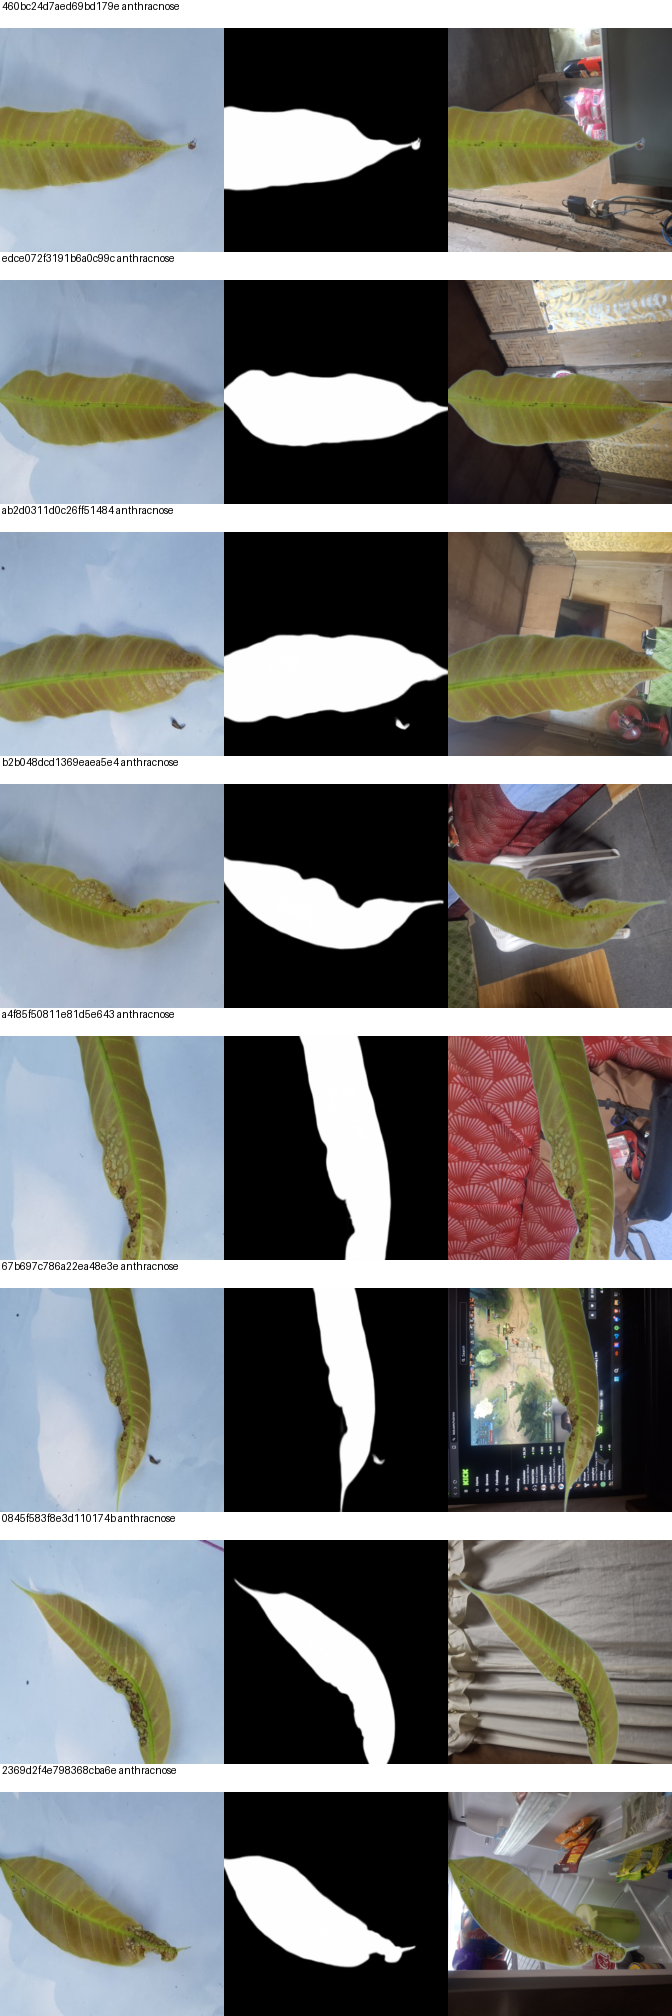

Review ALL pages here: /content/drive/MyDrive/mangoleaf_background_v3_1/20260918T193231Z-e2a0ac95/mask_previews
Nearly empty/full masks automatically excluded: 65


In [8]:
from IPython.display import display
preview_dir = RUN_DIR / 'mask_previews'
preview_dir.mkdir(exist_ok=True)
mask_rows = []
for job in jobs:
    with Image.open(job['maskPath']) as mask:
        hist = mask.convert('L').histogram()
        area = sum(hist[128:]) / sum(hist)
    mask_rows.append({**job, 'maskSha256': sha256_file(job['maskPath']),
                      'foregroundFraction': area, 'areaUsable': 0.05 <= area <= 0.98})
for start in range(0, len(mask_rows), 8):
    page = Image.new('RGB', (672, 8 * 252), 'white')
    draw = ImageDraw.Draw(page)
    for j, row in enumerate(mask_rows[start:start + 8]):
        with Image.open(row['path']) as source, Image.open(row['maskPath']) as mask, Image.open(background_records[(start+j) % len(background_records)]['path']) as bg:
            original = source.convert('RGB').resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
            small_mask = mask.convert('L').resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
            combined = preview_composite(original, small_mask, bg)
            for k, picture in enumerate([original, small_mask.convert('RGB'), combined]):
                page.paste(picture, (224*k, j*252+28))
            draw.text((2, j*252), row['id'] + ' ' + row['label'] + (' [AUTO-SKIP]' if not row['areaUsable'] else ''), fill='black')
    path = preview_dir / f'page-{start//8+1:03d}.jpg'
    page.save(path, quality=90)
    if start == 0: display(page)
write_json_once(RUN_DIR / 'mask_inventory.json', mask_rows)
print('Review ALL pages here:', preview_dir)
print('Nearly empty/full masks automatically excluded:', sum(not r['areaUsable'] for r in mask_rows))

In [12]:
MASK_REVIEW_COMPLETE = True
REJECT_MASK_IDS = ["5b5aab27bde8faaf9967"]  # Copy IDs from bad preview rows; originals stay in training.

approved_rows = review_masks(mask_rows, REJECT_MASK_IDS, MASK_REVIEW_COMPLETE)
approved_masks = {r['relativePath']: r for r in approved_rows if r['useForBlend']}
counts = Counter(r['label'] for r in approved_masks.values())
if any(counts[c] == 0 for c in CLASS_NAMES):
    raise ValueError('At least one reviewed usable mask per class is required. Review mask quality before training.')
REVIEW_PATH = RUN_DIR / 'mask_review.json'
write_json_once(REVIEW_PATH, {'reviewedAt': datetime.now(timezone.utc).isoformat(),
    'inputManifestSha256': MANIFEST_SHA256, 'rejectedIds': REJECT_MASK_IDS, 'masks': approved_rows})
REVIEW_SHA256 = sha256_file(REVIEW_PATH)
print('Approved masks per class:', dict(counts))
print('Expected fraction of training presentations with replaced backgrounds:',
      BLEND_PROBABILITY * len(approved_masks) / len(groups['train']))

Approved masks per class: {'anthracnose': 319, 'bacterial_black_spot': 207, 'bacterial_canker': 303, 'healthy': 423, 'mango_scab': 157, 'sooty_mold': 344}
Expected fraction of training presentations with replaced backgrounds: 0.48185816382627816


## 4. Train both arms

The approved mask changes only background pixels. Each image appears once per epoch;
there is no class-size inflation from extra copies. Background replacement is chosen
independently of the disease label and mixed with original presentations. Existing v3
flip/rotation/zoom/shear/brightness augmentation then runs on both arms.

Both arms reset the seed, use matching initial weights and epoch order, and receive
the same number of optimizer updates. Deterministic operations can be slower. Exact
results are not promised across different TensorFlow versions or hardware.

In [13]:
@tf.keras.utils.register_keras_serializable(package="mangoleaf")
class RandomShear(tf.keras.layers.Layer):
    # Random shear about the image centre. Keras ships no version-stable equivalent.
    def __init__(self, factor=0.2, fill_mode="NEAREST", **kwargs):
        super().__init__(**kwargs)
        self.factor = factor
        self.fill_mode = fill_mode

    def call(self, inputs, training=False):
        if not training:
            return inputs
        shape = tf.shape(inputs)
        n = shape[0]
        h = tf.cast(shape[1], tf.float32)
        w = tf.cast(shape[2], tf.float32)
        cx, cy = w / 2.0, h / 2.0

        sx = tf.random.uniform([n], -self.factor, self.factor)
        sy = tf.random.uniform([n], -self.factor, self.factor)
        one  = tf.ones_like(sx)
        zero = tf.zeros_like(sx)

        # Output-to-input map. a2 and b2 cancel the centre offset the shear introduces.
        transforms = tf.stack([one, sx, -sx * cy,
                               sy, one, -sy * cx,
                               zero, zero], axis=1)

        return tf.raw_ops.ImageProjectiveTransformV3(
            images=inputs,
            transforms=transforms,
            output_shape=shape[1:3],
            fill_value=0.0,
            interpolation="BILINEAR",
            fill_mode=self.fill_mode)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"factor": self.factor, "fill_mode": self.fill_mode})
        return cfg


def make_augmentation():
    return tf.keras.Sequential([
        tf.keras.layers.RandomFlip('horizontal_and_vertical', seed=SEED),
        tf.keras.layers.RandomRotation(30 / 360, fill_mode='nearest', seed=SEED),
        tf.keras.layers.RandomZoom(0.20, fill_mode='nearest', seed=SEED),
        RandomShear(0.20),
        tf.keras.layers.RandomBrightness(0.20, value_range=(0., 255.), seed=SEED),
    ])

In [14]:
def load_pixels(path):
    with Image.open(path) as picture:
        pixels = np.asarray(picture.convert('RGB'), dtype=np.float32)
    with tf.device('/CPU:0'):
        return tf.image.resize(pixels, IMAGE_SIZE, method='bilinear', antialias=False).numpy()


def load_training_sample(row, arm, epoch):
    pixels = load_pixels(row['path'])
    mask_row = approved_masks.get(row['relativePath']) if arm == 'background' else None
    background = choose_background(row['relativePath'], epoch, background_records, BLEND_PROBABILITY) if mask_row else None
    if background:
        if sha256_file(mask_row['maskPath']) != mask_row['maskSha256']:
            raise RuntimeError('Approved mask changed: ' + mask_row['id'])
        with Image.open(mask_row['maskPath']) as mask:
            alpha = np.asarray(mask.convert('L').resize(IMAGE_SIZE, Image.Resampling.BILINEAR), dtype=np.float32)[..., None] / 255.
        with Image.open(background['path']) as source:
            bg = np.asarray(ImageOps.fit(source.convert('RGB'), IMAGE_SIZE,
                            method=Image.Resampling.BILINEAR), dtype=np.float32)
        pixels = pixels * alpha + bg * (1 - alpha)
    return pixels, CLASS_NAMES.index(row['label'])


def make_dataset(records, arm=None, epoch=0, augment=None):
    def generate():
        order = list(range(len(records)))
        if arm:
            random.Random(stable_seed(SEED, epoch, 'order')).shuffle(order)
        for index in order:
            row = records[index]
            if arm:
                yield load_training_sample(row, arm, epoch)
            else:
                yield load_pixels(row['path']), CLASS_NAMES.index(row['label'])
    ds = tf.data.Dataset.from_generator(generate, output_signature=(
        tf.TensorSpec((*IMAGE_SIZE, 3), tf.float32), tf.TensorSpec((), tf.int32)))
    ds = ds.batch(BATCH_SIZE)
    ds = ds.apply(tf.data.experimental.assert_cardinality(math.ceil(len(records) / BATCH_SIZE)))
    if augment is not None:
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=1)
    return ds.prefetch(1)


def make_model():
    base = tf.keras.applications.MobileNetV3Large(input_shape=(*IMAGE_SIZE, 3),
        include_top=False, weights='imagenet', include_preprocessing=True)
    base.trainable = False
    inputs = tf.keras.Input(shape=(*IMAGE_SIZE, 3), name='input_image')
    x = base(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D(name='gap')(x)
    x = tf.keras.layers.Dropout(0.2, name='dropout')(x)
    logits = tf.keras.layers.Dense(len(CLASS_NAMES), name='logits')(x)
    probs = tf.keras.layers.Activation('softmax', dtype='float32', name='probs')(logits)
    return tf.keras.Model(inputs, probs, name='mangoleaf_v3_1'), base


def weight_digest(model):
    digest = hashlib.sha256()
    for variable in model.weights:
        array = variable.numpy()
        digest.update(str(array.shape).encode())
        digest.update(array.tobytes())
    return digest.hexdigest()


def calibrate_and_save(model, arm_dir):
    from scipy.optimize import minimize_scalar
    logits_model = tf.keras.Model(model.inputs, model.get_layer('logits').output)
    logits = logits_model.predict(make_dataset(groups['val']), verbose=0).astype(np.float64)
    labels = np.array([CLASS_NAMES.index(r['label']) for r in groups['val']])
    def nll(temperature):
        z = logits / temperature
        z -= z.max(axis=1, keepdims=True)
        return float((np.log(np.exp(z).sum(axis=1)) - z[np.arange(len(labels)), labels]).mean())
    result = minimize_scalar(nll, bounds=(0.25, 20.0), method='bounded')
    if not result.success or not math.isfinite(float(result.fun)):
        raise RuntimeError('Temperature fitting failed; no calibrated model exported.')
    # T=1 remains a valid candidate if bounded optimization does not improve NLL.
    temperature = float(result.x) if result.fun < nll(1.0) else 1.0
    layer = model.get_layer('logits')
    weights, bias = layer.get_weights()
    layer.set_weights([weights / temperature, bias / temperature])
    path = arm_dir / 'model_calibrated.keras'
    model.save(path)
    loaded = tf.keras.models.load_model(path, compile=False, safe_mode=True)
    probe = tf.convert_to_tensor(load_pixels(groups['val'][0]['path'])[None])
    np.testing.assert_allclose(model(probe, training=False).numpy(), loaded(probe, training=False).numpy(), rtol=1e-5, atol=1e-6)
    return temperature, {'before': nll(1.0), 'after': nll(temperature)}, path

In [15]:
if not tf.config.list_physical_devices('GPU'):
    raise RuntimeError('Select a Colab GPU runtime before training both models.')
if (sha256_file(REVIEW_PATH) != REVIEW_SHA256 or sha256_file(MANIFEST_PATH) != MANIFEST_SHA256
        or sha256_file(PLAN_PATH) != PLAN_SHA256):
    raise RuntimeError('Frozen plan, review, or input manifest changed; start a new experiment.')
plan = json.loads(PLAN_PATH.read_text(encoding='utf-8'))
actual_settings = {'seed': SEED, 'blendProbability': BLEND_PROBABILITY, 'batchSize': BATCH_SIZE,
                   'stage1': [STAGE1_EPOCHS, STAGE1_LR], 'stage2': [STAGE2_EPOCHS, STAGE2_LR]}
if any(plan[k] != v for k, v in actual_settings.items()):
    raise RuntimeError('Training settings changed after the plan was saved; start a new experiment.')
approved_rows = json.loads(REVIEW_PATH.read_text(encoding='utf-8'))['masks']
approved_masks = {r['relativePath']: r for r in approved_rows if r['useForBlend']}
verify_bundle_inputs(manifest, sum(groups.values(), []))
verify_records_unchanged(all_records)
class_counts = Counter(r['label'] for r in groups['train'])
class_weight = {i: len(groups['train']) / (len(CLASS_NAMES) * class_counts[c]) for i, c in enumerate(CLASS_NAMES)}
arm_results = {}
initial_digest = None
for arm in ['control', 'background']:
    arm_dir = RUN_DIR / arm
    arm_dir.mkdir(exist_ok=False)
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model, base_model = make_model()
    digest = weight_digest(model)
    if initial_digest is None: initial_digest = digest
    if initial_digest != digest:
        raise RuntimeError('The two arms did not receive identical initial weights.')
    augment = make_augmentation()
    histories = []
    completed_epochs = 0
    for stage, epochs, learning_rate in [(1, STAGE1_EPOCHS, STAGE1_LR), (2, STAGE2_EPOCHS, STAGE2_LR)]:
        if stage == 2:
            base_model.trainable = True
            for layer in base_model.layers:
                if isinstance(layer, tf.keras.layers.BatchNormalization): layer.trainable = False
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate),
                      loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        checkpoint = arm_dir / f'stage{stage}_best.weights.h5'
        best_loss = float('inf')
        for epoch in range(epochs):
            print(arm, 'stage', stage, 'epoch', epoch + 1, '/', epochs)
            history = model.fit(make_dataset(groups['train'], arm, completed_epochs, augment),
                validation_data=make_dataset(groups['val']), epochs=1, class_weight=class_weight, verbose=2)
            metrics = {k: float(v[-1]) for k, v in history.history.items()}
            if not all(math.isfinite(v) for v in metrics.values()):
                raise RuntimeError('Non-finite training metrics; stopping instead of exporting a broken model.')
            histories.append({'stage': stage, 'epoch': completed_epochs + 1, **metrics})
            if metrics['val_loss'] < best_loss:
                best_loss = metrics['val_loss']
                model.save_weights(checkpoint)
            completed_epochs += 1
        model.load_weights(checkpoint)
    write_json_once(arm_dir / 'training_history.json', histories)
    temperature, calibration, model_path = calibrate_and_save(model, arm_dir)
    version = 'model-v3.1.0' if arm == 'background' else 'model-v3.1.0-control'
    info = {'trial': '3.1', 'arm': arm, 'modelVersion': version, 'classes': CLASS_NAMES,
        'temperature': temperature, 'temperatureFoldedIntoWeights': True,
        'confidenceThreshold': 0.70, 'modelSha256': sha256_file(model_path),
        'inputManifestSha256': MANIFEST_SHA256, 'maskReviewSha256': REVIEW_SHA256,
        'planSha256': PLAN_SHA256,
        'initialWeightsSha256': initial_digest, 'runtime': RUNTIME,
        'validationCalibrationNll': calibration, 'evaluationStatus': EVALUATION_STATUS,
        'evaluationNotes': EVALUATION_NOTES, 'baseLayerName': base_model.name}
    write_json_once(arm_dir / 'resume_info.json', info)
    arm_results[arm] = info
    print(arm, 'saved:', model_path, 'temperature:', temperature)
verify_records_unchanged(all_records)
write_json_once(RUN_DIR / 'training_complete.json', {'arms': arm_results,
    'inputManifestSha256': MANIFEST_SHA256, 'maskReviewSha256': REVIEW_SHA256,
    'planSha256': PLAN_SHA256,
    'finishedAt': datetime.now(timezone.utc).isoformat(), 'testPredictionsRun': False})
print('BOTH MODELS READY. Set TRAINING_RUN in the v3.2 threshold notebook to:', RUN_DIR)

12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
control stage 1 epoch 1 / 5
57/57 - 64s - 1s/step - accuracy: 0.7015 - loss: 0.8087 - val_accuracy: 0.8798 - val_loss: 0.3065
control stage 1 epoch 2 / 5
57/57 - 52s - 919ms/step - accuracy: 0.8939 - loss: 0.3416 - val_accuracy: 0.9437 - val_loss: 0.1904
control stage 1 epoch 3 / 5
57/57 - 51s - 899ms/step - accuracy: 0.9247 - loss: 0.2593 - val_accuracy: 0.9309 - val_loss: 0.1748
control stage 1 epoch 4 / 5
57/57 - 51s - 901ms/step - accuracy: 0.9467 - loss: 0.2204 - val_accuracy: 0.9642 - val_loss: 0.1418
control stage 1 epoch 5 / 5
57/57 - 54s - 945ms/step - accuracy: 0.9434 - loss: 0.1957 - val_accuracy: 0.9488 - val_loss: 0.1458
control stage 2 epoch 1 / 10
57/57 - 71s - 1s/step - accuracy: 0.9555 - loss: 0.1711 - val_accuracy: 0.9565 - val_loss: 0.1311
control stage 2 epoch 2 / 10
57/57 - 55s - 964ms/step - accuracy: 0.9615 - loss: 0.1600 - val_accuracy: 0.9591 - val_loss: 0.1259
control stage 2 epoch 3 / 10
57/57 - 58s - 1s/step

## 5. Optional validation Grad-CAM comparison

These are diagnostic validation examples, not a test score or proof that the model
ignores backgrounds. Both models see the same first sorted image per class. Values
are calibrated top-class probabilities; this figure applies no rejection thresholds.
The v3.2 notebook reports wrong diagnoses and rejected images separately.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import hashlib, json
from pathlib import Path
import numpy as np
import tensorflow as tf
from PIL import Image, __version__ as pillow_version

# training-run folder
GRADCAM_RUN = '/content/drive/MyDrive/mangoleaf_background_v3_1/20260918T193231Z-e2a0ac95'


def restore_gradcam_inputs(run_dir, runtime):
    run_dir = Path(run_dir)
    completed_path = run_dir / 'training_complete.json'
    if not completed_path.is_file():
        raise FileNotFoundError(
            f'No completed training bundle at {completed_path}. '
            'Choose the original run folder where BOTH MODELS READY was printed.')
    completed = json.loads(completed_path.read_text(encoding='utf-8'))
    manifest_path = run_dir / 'input_manifest.json'
    if hashlib.sha256(manifest_path.read_bytes()).hexdigest() != completed['inputManifestSha256']:
        raise RuntimeError('The saved input manifest changed after training.')
    saved_manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
    class_names = saved_manifest['classes']
    arms = completed['arms']
    if set(arms) != {'control', 'background'}:
        raise ValueError('Grad-CAM requires both completed model arms.')
    for arm, info in arms.items():
        saved_info = json.loads((run_dir / arm / 'resume_info.json').read_text(encoding='utf-8'))
        if (saved_info != info or info['classes'] != class_names or info['trial'] != '3.1'
                or info['inputManifestSha256'] != completed['inputManifestSha256']):
            raise RuntimeError(f'{arm}: metadata does not match the completed training run.')
        for package in ['tensorflow', 'keras', 'numpy', 'pillow']:
            if info['runtime'][package] != runtime[package]:
                raise RuntimeError(f'{package}: use training version {info["runtime"][package]} '
                                   f'for this comparison; current version is {runtime[package]}.')
        model_path = run_dir / arm / 'model_calibrated.keras'
        if hashlib.sha256(model_path.read_bytes()).hexdigest() != info['modelSha256']:
            raise RuntimeError(f'{arm}: saved model changed after training.')
    validation_rows = sorted((r for r in saved_manifest['images'] if r['subset'] == 'val'),
                             key=lambda r: r['relativePath'])
    if {r['label'] for r in validation_rows} != set(class_names):
        raise ValueError('The saved validation records do not contain every class.')
    for label in class_names:
        row = next(r for r in validation_rows if r['label'] == label)
        if hashlib.sha256(Path(row['path']).read_bytes()).hexdigest() != row['sha256']:
            raise RuntimeError('Validation image changed after training: ' + row['path'])
    return class_names, {'val': validation_rows}, arms


if GRADCAM_RUN.strip():
    RUN_DIR = Path(GRADCAM_RUN)
elif 'RUN_DIR' not in globals():
    raise ValueError('Set GRADCAM_RUN to the completed training-run folder in Google Drive.')
gradcam_runtime = {'tensorflow': tf.__version__, 'keras': tf.keras.__version__,
                   'numpy': np.__version__, 'pillow': pillow_version}
CLASS_NAMES, groups, arm_results = restore_gradcam_inputs(RUN_DIR, gradcam_runtime)
IMAGE_SIZE = (224, 224)
tf.keras.mixed_precision.set_global_policy('float32')


def load_pixels(path):
    with Image.open(path) as picture:
        pixels = np.asarray(picture.convert('RGB'), dtype=np.float32)
    with tf.device('/CPU:0'):
        return tf.image.resize(pixels, IMAGE_SIZE, method='bilinear', antialias=False).numpy()


print('Grad-CAM inputs restored from:', RUN_DIR)


Mounted at /content/drive
Grad-CAM inputs restored from: /content/drive/MyDrive/mangoleaf_background_v3_1/20260918T193231Z-e2a0ac95


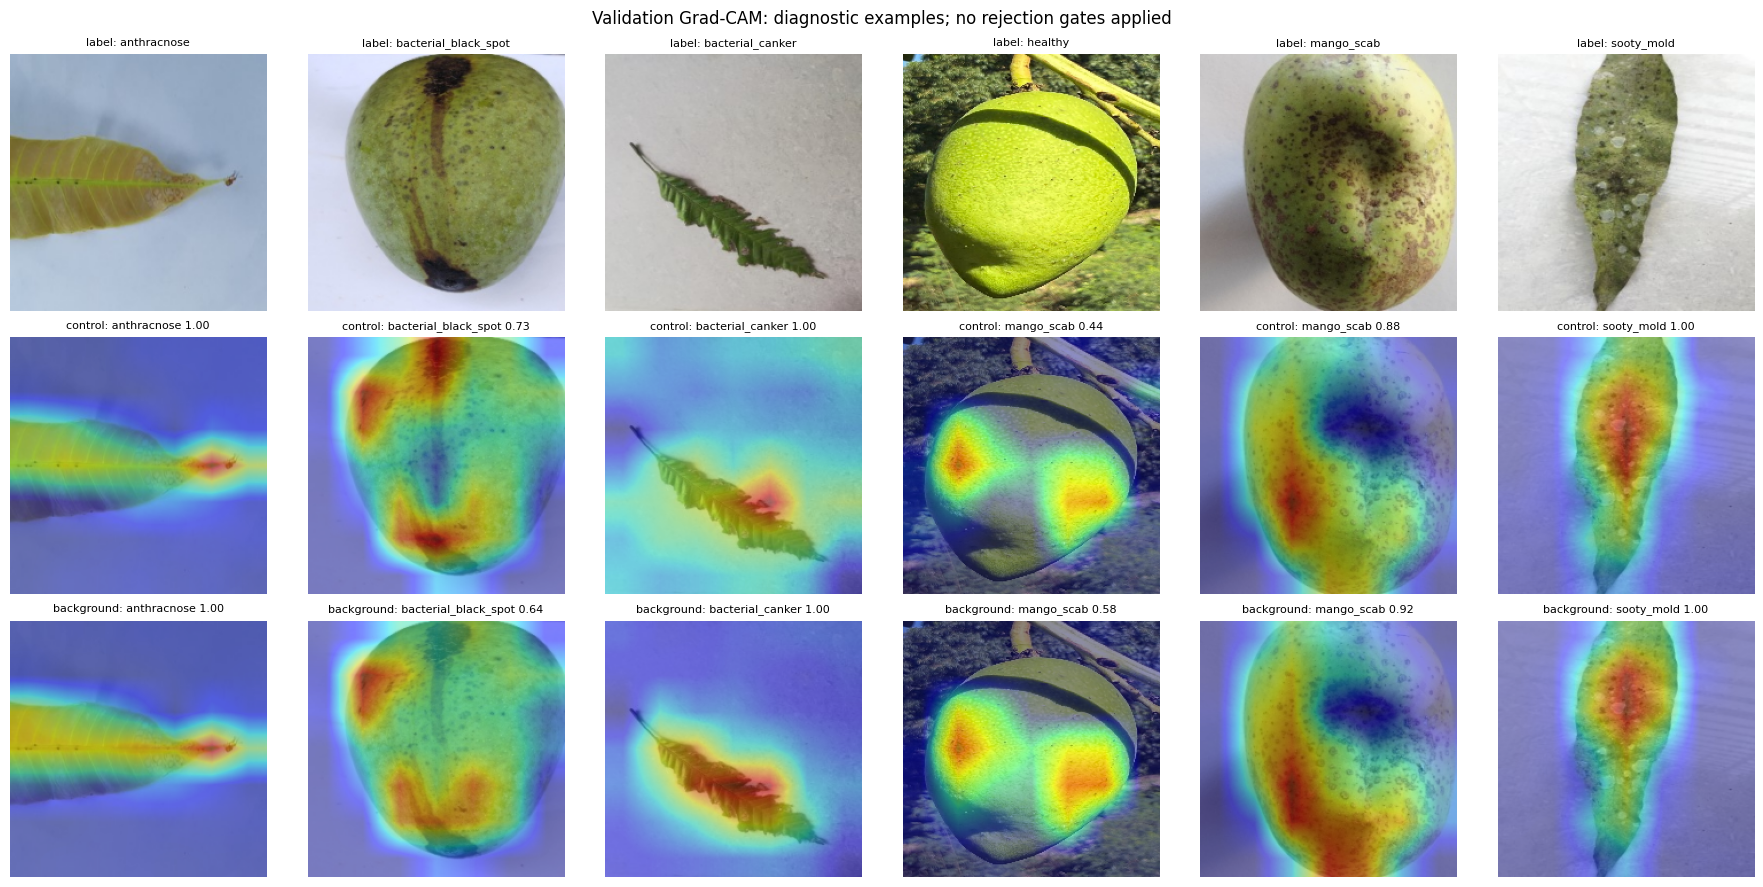

In [3]:
import matplotlib.pyplot as plt
required = ['CLASS_NAMES', 'groups', 'load_pixels', 'RUN_DIR', 'arm_results', 'IMAGE_SIZE', 'tf']
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError('Run the Grad-CAM restoration cell immediately above first. Missing: ' + ', '.join(missing))
picked = [next(r for r in groups['val'] if r['label'] == c) for c in CLASS_NAMES]
fig, axes = plt.subplots(3, len(CLASS_NAMES), figsize=(18, 9))
for col, row in enumerate(picked):
    axes[0, col].imshow(load_pixels(row['path']).astype('uint8'))
    axes[0, col].set_title('label: ' + row['label'], fontsize=8)
for line, arm in enumerate(['control', 'background'], 1):
    model = tf.keras.models.load_model(RUN_DIR / arm / 'model_calibrated.keras', compile=False, safe_mode=True)
    base = model.get_layer(arm_results[arm]['baseLayerName'])
    for col, row in enumerate(picked):
        pixels = load_pixels(row['path'])
        batch = tf.convert_to_tensor(pixels[None])
        with tf.GradientTape() as tape:
            feature = base(batch, training=False)
            tape.watch(feature)
            h = model.get_layer('gap')(feature)
            h = model.get_layer('dropout')(h, training=False)
            logits = model.get_layer('logits')(h)
            index = tf.argmax(logits[0])
            score = logits[:, index]
        grads = tape.gradient(score, feature)
        heat = tf.nn.relu(tf.reduce_sum(feature[0] * tf.reduce_mean(grads, axis=(0, 1, 2)), axis=-1))
        heat = heat / (tf.reduce_max(heat) + 1e-9)
        heat = tf.image.resize(heat[..., None], IMAGE_SIZE).numpy()[..., 0]
        prob = float(model(batch, training=False).numpy()[0, int(index)])
        axes[line, col].imshow(pixels.astype('uint8'))
        axes[line, col].imshow(heat, cmap='jet', alpha=0.45, vmin=0, vmax=1)
        axes[line, col].set_title(f'{arm}: {CLASS_NAMES[int(index)]} {prob:.2f}', fontsize=8)
for ax in axes.flat: ax.axis('off')
fig.suptitle('Validation Grad-CAM: diagnostic examples; no rejection gates applied')
fig.tight_layout()
fig.savefig(RUN_DIR / 'validation_grad_cam.png', dpi=150)
plt.show()

## Next: threshold fitting v3.2

Open `MangoLeaf_AI_Threshold_Fitting_v3_2.ipynb` and paste the printed training-run
directory into `TRAINING_RUN`. It fits separate thresholds for both models using
validation and OOD tune, freezes **both** selections, then evaluates both against
the same test and OOD report images. The old v3/v3.1 threshold notebooks remain
historical workflows for the original v3 weights, not these new models.

Save this completed notebook separately as `MangoLeaf_AI_Training_v3_1_Results.ipynb`.
No TensorFlow.js export or deployment is performed. Adoption needs metric review,
browser conversion/parity checks, and real field evaluation. One paired seed is an
exploratory comparison; repeat predeclared seeds before claiming a general benefit.

Source: the repository's `notebooks/v3/` training notebooks. References:
[background dependence](https://arxiv.org/abs/2006.09994),
[Grad-CAM](https://arxiv.org/abs/1610.02391),
[rembg](https://github.com/danielgatis/rembg/tree/v2.0.67),
[TensorFlow determinism](https://www.tensorflow.org/api_docs/python/tf/config/experimental/enable_op_determinism).